# 01 · Missingness, duplicate patterns, and preparation

Test whether the workbook can support a consistent chronology and a unique incident grain. Work on in-memory views of the workbook and compare key transformations against the approved export. Only aggregate outputs are shown.

[Previous](00_dataset_and_source_assessment.ipynb) · [Notebook guide](../README.md#notebook-guide) · [Next](02_eda_statistics_and_visualization.ipynb)

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from bd_safety.cleaning import ambiguous_date, parse_date
from IPython.display import Image, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "src/bd_safety").is_dir(), (
    "Open from the project root or notebooks directory."
)
REPORTS = ROOT / "reports"
TABLES = REPORTS / "tables"


WORKBOOK = ROOT / "data/raw/Modified_Accident_Dataset final.xlsx"
quality = json.loads((REPORTS / "data_quality.json").read_text())

## How much is missing, and what is duplicated?

Read the workbook once. Count actual missing cells and exact duplicates across all columns before any normalization. Preserve Excel row numbers as provenance keys. Report concentrated values using the inventory without displaying their raw text.

In [2]:
raw = pd.read_excel(WORKBOOK, engine="openpyxl")
duplicate = raw.duplicated()
retained = raw.loc[~duplicate, ["Date ", "Year", "ID", "Accident Serial No"]]
source_rows = np.flatnonzero(~duplicate.to_numpy()) + 2
assert int(duplicate.sum()) == quality["exact_duplicate_rows_removed"]
assert int(raw.isna().sum().sum()) == quality["raw_null_cells"]
inventory = pd.read_csv(TABLES / "column_inventory.csv")
display(
    pd.Series(
        {
            "raw rows": len(raw),
            "raw null cells": int(raw.isna().sum().sum()),
            "exact duplicates": int(duplicate.sum()),
            "retained rows": len(retained),
        }
    )
)
display(
    inventory.nlargest(6, "largest_value_share")[
        [
            "original_column",
            "raw_nulls",
            "missing_after_token_normalization",
            "distinct_nonmissing",
            "largest_value_share",
        ]
    ]
)

raw rows            47680
raw null cells          0
exact duplicates        4
retained rows       47676
dtype: int64

,original_column,raw_nulls,missing_after_token_normalization,distinct_nonmissing,largest_value_share
15,Road Surface Type,0,0,2,0.999979
18,Place characteristic,0,0,2,0.999979
20,Road Surface Condition,0,0,4,0.999769
8,Vehicle Count,0,0,3,0.979782
16,Road nature,0,0,3,0.973008
19,Type of Road connection point,0,0,7,0.971141


Four exact duplicates are removed from analytical preparation. Zero raw null cells can coexist with unusable dates and highly repeated field values.

## Do parsed dates agree with declared years?

Use the established date parser for Excel-native dates and day-first slash strings. Keep the declared year beside the parsed year and flag disagreements. Invalid or ambiguous dates are excluded from a strict chronology cohort.

parseable_dates                47533
invalid_dates                    143
date_year_conflicts            47533
strict_temporal_cohort_rows        0
dtype: int64

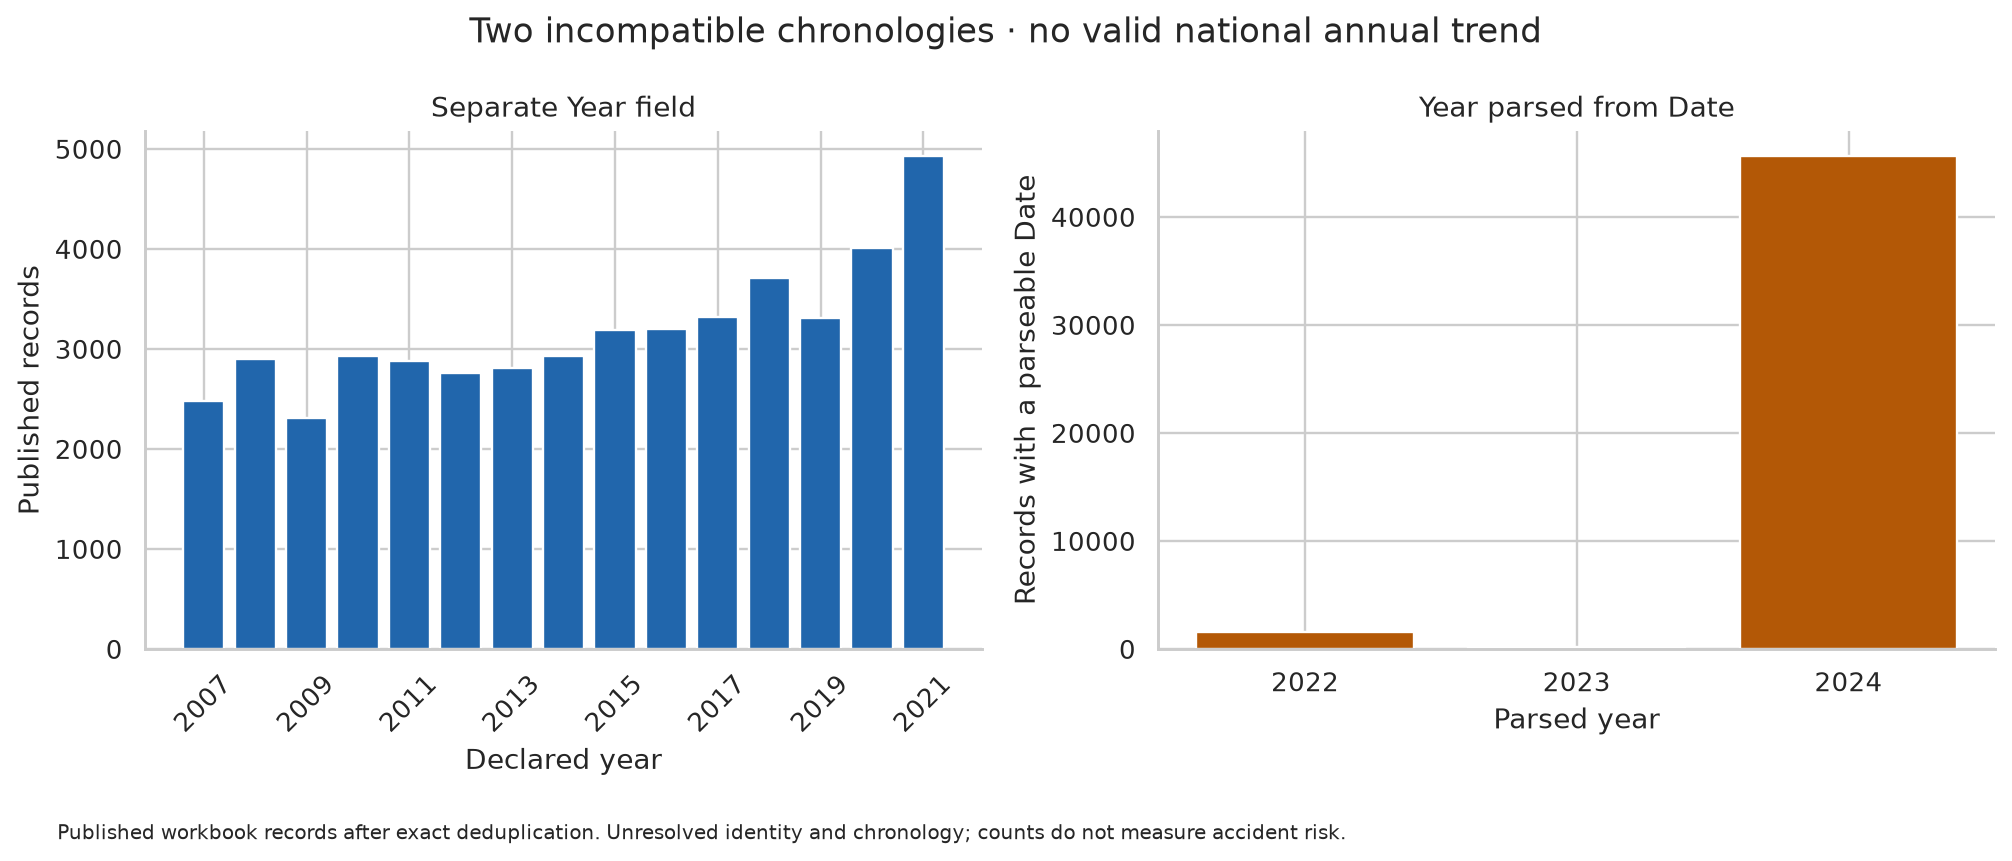

In [3]:
parsed = pd.to_datetime(retained["Date "].map(parse_date))
ambiguous = retained["Date "].map(ambiguous_date)
conflict = (parsed.notna() & parsed.dt.year.ne(retained["Year"])).fillna(False)
consistent = parsed.notna() & ~conflict & ~ambiguous
chronology = {
    "parseable_dates": int(parsed.notna().sum()),
    "invalid_dates": int(parsed.isna().sum()),
    "date_year_conflicts": int(conflict.sum()),
    "strict_temporal_cohort_rows": int(consistent.sum()),
}
assert all(value == quality[key] for key, value in chronology.items())
display(pd.Series(chronology))
display(Image(filename=str(REPORTS / "figures/01_year_coverage.png"), width=900))

All 47,533 parseable dates disagree with the declared year and 143 dates fail parsing. The declared years span 2007–2021 while parsed dates fall in 2022–2024. The strict cohort is empty.

## Can an identifier rescue incident identity?

Check how many distinct IDs and serial numbers remain. Compare group summaries based on normalized Date, Time, Location, Narrative and Vehicle Info. These descriptors are used only as matching candidates. Reconcile the approved analytical export’s row positions and date flags with the direct calculation.

distinct source IDs                        17497
distinct serial numbers                    47305
candidate groups                            2321
groups with conflicting fatality values     1929
records without parsed latitude               19
dtype: int64

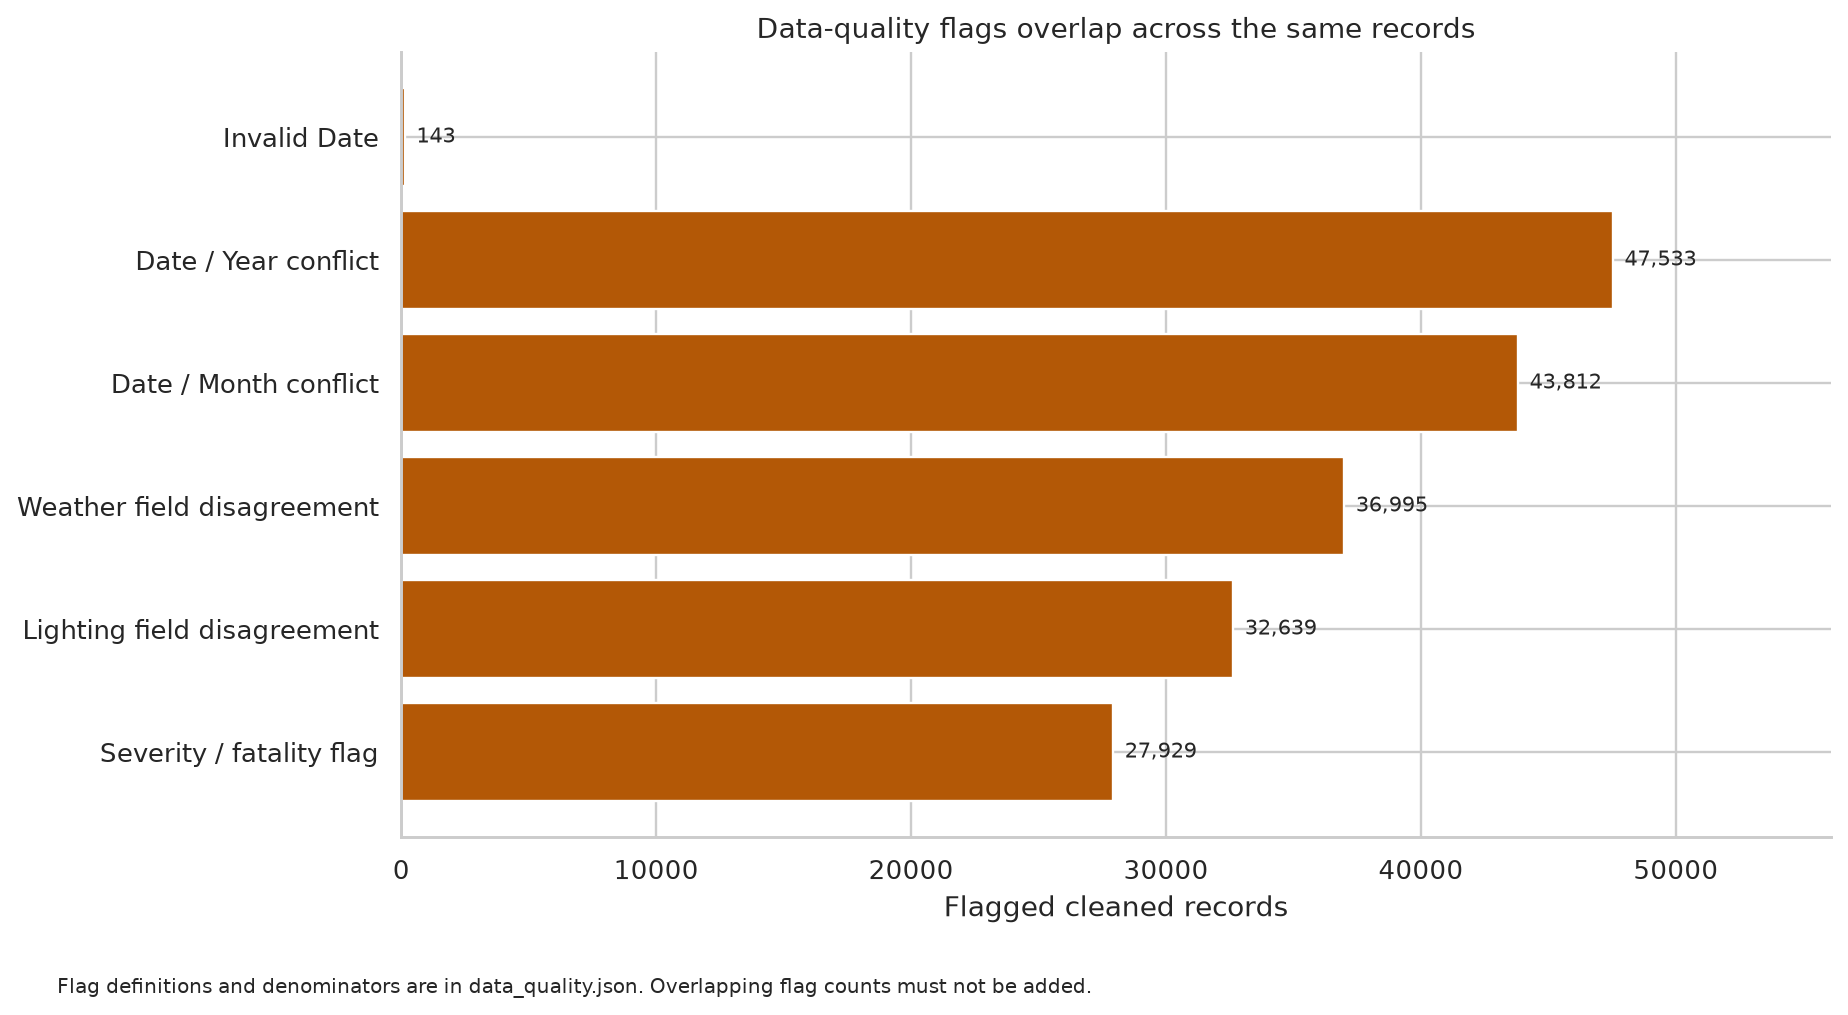

In [4]:
prepared = pd.read_csv(
    ROOT / "data/processed/cleaned_records.csv",
    usecols=["source_row", "date_year_conflict", "latitude"],
)
np.testing.assert_array_equal(prepared["source_row"], source_rows)
np.testing.assert_array_equal(prepared["date_year_conflict"], conflict)
groups = pd.read_csv(TABLES / "descriptor_groups.csv")
identity = pd.Series(
    {
        "distinct source IDs": retained["ID"].nunique(),
        "distinct serial numbers": retained["Accident Serial No"].nunique(),
        "candidate groups": len(groups),
        "groups with conflicting fatality values": groups["fatality_values"]
        .gt(1)
        .sum(),
        "records without parsed latitude": prepared["latitude"].isna().sum(),
    }
)
assert (
    identity["groups with conflicting fatality values"]
    == quality["groups_with_conflicting_fatality_values"]
)
display(identity)
display(Image(filename=str(REPORTS / "figures/09_quality_flags.png"), width=900))

There are 17,497 distinct source IDs among 47,676 retained rows. In 1,929 of 2,321 candidate descriptor groups, fatality values disagree. Quality flags can overlap on a row, so adding them would overcount affected records. Carry the verified row grain into descriptive exploration.

[Previous](00_dataset_and_source_assessment.ipynb) · [Notebook guide](../README.md#notebook-guide) · [Next](02_eda_statistics_and_visualization.ipynb)